## **Samuel Christopher - 2802545466**
---

### **Explanation video link**: https://drive.google.com/drive/folders/1y-I4MHxqkMWMBRtFkAbz8PggBhEiC-J8?usp=sharing

# Credit Score Classification: Exploration and Modelling

This notebook documents data exploration, preprocessing, model comparison, evaluation, and interpretation for the Model Deployment Final Project.

**Dataset:** data_C.csv (Credit Score Classification: Good, Standard, Poor)

In [ ]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import learning_curve

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT))

from src.models.pipeline_local import CreditDataPreprocessor, CreditScorePipeline

DATA_PATH    = ROOT / "data"   / "data_C.csv"
MODEL_PATH   = ROOT / "models" / "model_best.pkl"
METRICS_PATH = ROOT / "models" / "metrics.json"

plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (8, 4)})
pd.set_option("display.max_columns", 40)

## 1. Load Dataset

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Shape  : {df.shape}")
print(f"Columns: {df.columns.tolist()}")
display(df.head())

Shape  : (25000, 29)
Columns: ['Unnamed: 0', 'ID', 'Customer_ID', 'Month', 'Name', 'Age', 'SSN', 'Occupation', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Credit_History_Age', 'Payment_of_Min_Amount', 'Total_EMI_per_month', 'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance', 'Credit_Score']


,Unnamed: 0,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0,0x20419,CUS_0x36e1,August,Gellero,35,132-77-4921,Journalist,20364.57,1626.047500,6,8,32,3,"Personal Loan, Student Loan, and Mortgage Loan",23,9,10.3,11.0,Standard,2500.04,27.576478,9 Years and 8 Months,Yes,26.168109,92.51897591535379,High_spent_Small_value_payments,303.917665,Standard
1,1,0x4579,CUS_0x2a61,August,NaN,46,753-68-0048,Teacher,9786.86,951.571667,9,10,1663,2,"Personal Loan, and Student Loan",58,14,15.53,6.0,Standard,2149.9,23.451285,NaN,Yes,11.564437,54.46174813453877,Low_spent_Medium_value_payments,309.130981,Poor
2,2,0x1b923,CUS_0x788b,June,Ben Klaymane,19,276-42-6585,_______,146880.84,12372.070000,1,6,2,1,Auto Loan,25,4,5.04,1.0,Good,387.53,31.100297,24 Years and 3 Months,No,98.031931,478.3574716999517,High_spent_Small_value_payments,920.817597,Standard
3,3,0x8ac9,CUS_0x5534,April,Aubinr,39,246-34-3138,Developer,23200.82,NaN,3,7,5,0,NaN,30,15,24.73,6.0,Standard,987.07,26.786925,17 Years and 7 Months,Yes,0.000000,65.84983488267585,Low_spent_Large_value_payments,391.890332,Standard
4,4,0x24a41,CUS_0x104f,April,Markm,20,264-84-8069,Architect,11336.835,992.736250,4,1405,14,6,"Auto Loan, Payday Loan, Student Loan, Auto Loa...",30,19,16.44,7.0,Standard,177.98,24.001752,14 Years and 7 Months,Yes,35.562731,NaN,Low_spent_Small_value_payments,228.245999,Standard


## 2. Target Distribution

This is a **multi-class classification** problem with 3 Credit Score classes.
The class distribution is checked here to assess whether imbalance needs to be addressed during training.

=== Target Distribution ===


,count,pct (%)
Credit_Score,,
Standard,13282,53.1
Poor,7268,29.1
Good,4450,17.8


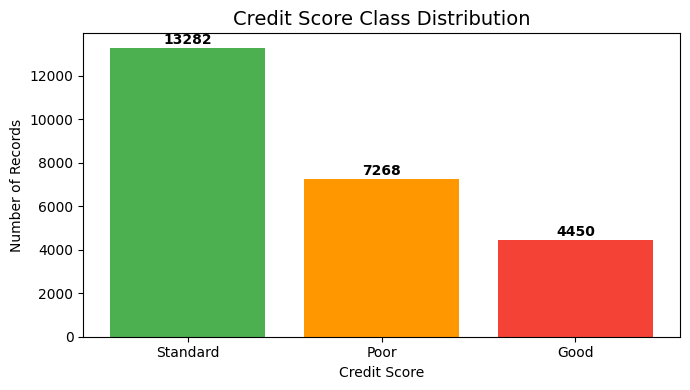


Imbalance ratio (majority/minority): 2.98x
Note: The dataset is imbalanced. A stratified split is used during training.


In [3]:
target_counts = df["Credit_Score"].value_counts()
target_pct    = target_counts / len(df) * 100

print("=== Target Distribution ===")
display(
    pd.DataFrame({"count": target_counts, "pct (%)": target_pct.round(1)})
)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(target_counts.index, target_counts.values,
              color=["#4CAF50", "#FF9800", "#F44336"])
for bar, cnt in zip(bars, target_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
            str(cnt), ha="center", va="bottom", fontweight="bold")
ax.set_title("Credit Score Class Distribution", fontsize=14)
ax.set_xlabel("Credit Score")
ax.set_ylabel("Number of Records")
plt.tight_layout()
plt.show()

# Imbalance ratio
print(f"\nImbalance ratio (majority/minority): {target_counts.max()/target_counts.min():.2f}x")
print("Note: The dataset is imbalanced. A stratified split is used during training.")

## 3. Exploratory Data Analysis (EDA)

### 3.1 Data Types and Missing Values

In [4]:
print("=== Data Types ===")
print(df.dtypes)

print("\n=== Missing Values ===")
missing     = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df  = pd.DataFrame({"missing_count": missing, "missing_pct (%)": missing_pct})
display(missing_df[missing_df["missing_count"] > 0].sort_values("missing_pct (%)", ascending=False))

=== Data Types ===
Unnamed: 0                    int64
ID                           object
Customer_ID                  object
Month                        object
Name                         object
Age                          object
SSN                          object
Occupation                   object
Annual_Income                object
Monthly_Inhand_Salary       float64
Num_Bank_Accounts             int64
Num_Credit_Card               int64
Interest_Rate                 int64
Num_of_Loan                  object
Type_of_Loan                 object
Delay_from_due_date           int64
Num_of_Delayed_Payment       object
Changed_Credit_Limit         object
Num_Credit_Inquiries        float64
Credit_Mix                   object
Outstanding_Debt             object
Credit_Utilization_Ratio    float64
Credit_History_Age           object
Payment_of_Min_Amount        object
Total_EMI_per_month         float64
Amount_invested_monthly      object
Payment_Behaviour            object
Monthly_B

,missing_count,missing_pct (%)
Monthly_Inhand_Salary,3836,15.34
Type_of_Loan,2852,11.41
Name,2430,9.72
Credit_History_Age,2240,8.96
Num_of_Delayed_Payment,1792,7.17
Amount_invested_monthly,1134,4.54
Num_Credit_Inquiries,472,1.89
Monthly_Balance,301,1.20


### 3.2 Dirty Values

Several columns store numeric values as strings with a trailing underscore suffix (for example `35_`),
or contain invalid placeholder values in categorical columns.
All of these are identified below and cleaned before modelling.

In [5]:
print("=== Credit_Mix unique values ===")
print(df["Credit_Mix"].unique())
print("  -> Value '_' is a dirty placeholder, will be replaced with NaN then imputed.")

print("\n=== Payment_Behaviour unique values ===")
print(df["Payment_Behaviour"].unique())
print("  -> Value '!@9#%8' is a dirty placeholder, will be replaced with NaN then imputed.")

print("\n=== Payment_of_Min_Amount unique values ===")
print(df["Payment_of_Min_Amount"].unique())
print("  -> Value 'NM' (Not Mentioned) is kept as its own valid category.")

print("\n=== Occupation unique values ===")
print(df["Occupation"].unique())
print("  -> Value '_______' is a dirty placeholder, will be replaced with NaN then imputed.")

print("\n=== Sample dirty numeric strings ===")
dirty_age = df["Age"][pd.to_numeric(df["Age"], errors="coerce").isna()].unique()[:5]
print(f"Age dirty samples     : {dirty_age}  -> strip '_', convert to int")

dirty_inc = df["Annual_Income"][pd.to_numeric(df["Annual_Income"], errors="coerce").isna()].unique()[:3]
print(f"Annual_Income dirty   : {dirty_inc}  -> strip '_', convert to float")

print("\n=== Credit_History_Age sample ===")
print(df["Credit_History_Age"].dropna().head(5).tolist())
print("  -> Will be parsed into total months (years * 12 + months).")

=== Credit_Mix unique values ===
['Standard' 'Good' 'Bad' '_']
  -> Value '_' is a dirty placeholder, will be replaced with NaN then imputed.

=== Payment_Behaviour unique values ===
['High_spent_Small_value_payments' 'Low_spent_Medium_value_payments'
 'Low_spent_Large_value_payments' 'Low_spent_Small_value_payments'
 '!@9#%8' 'High_spent_Medium_value_payments'
 'High_spent_Large_value_payments']
  -> Value '!@9#%8' is a dirty placeholder, will be replaced with NaN then imputed.

=== Payment_of_Min_Amount unique values ===
['Yes' 'No' 'NM']
  -> Value 'NM' (Not Mentioned) is kept as its own valid category.

=== Occupation unique values ===
['Journalist' 'Teacher' '_______' 'Developer' 'Architect' 'Doctor'
 'Media_Manager' 'Accountant' 'Entrepreneur' 'Lawyer' 'Writer' 'Engineer'
 'Manager' 'Musician' 'Scientist' 'Mechanic']
  -> Value '_______' is a dirty placeholder, will be replaced with NaN then imputed.

=== Sample dirty numeric strings ===
Age dirty samples     : ['28_' '53_' '26_'

### 3.3 Outlier Analysis

Before clipping, we visualise the distribution of numeric features to quantify how many values
fall outside the [1st, 99th] percentile range. This justifies the clipping step in preprocessing
and shows which features have the most extreme values.

=== Outlier Count per Feature (beyond [1st, 99th] percentile) ===


,feature,p1,p99,n_outliers,pct_outliers
8,Outstanding_Debt,27.94,4813.03,500,2.00
9,Credit_Utilization_Ratio,22.77,42.53,500,2.00
0,Annual_Income,7476.26,179078.28,499,2.00
11,Monthly_Balance,67.64,1149.38,494,2.00
1,Monthly_Inhand_Salary,524.99,13943.25,422,1.99
7,Num_of_Delayed_Payment,0.00,27.00,353,1.52
6,Delay_from_due_date,0.00,61.00,325,1.30
2,Num_Bank_Accounts,0.00,549.07,255,1.02
3,Num_Credit_Card,1.00,822.00,253,1.01
4,Interest_Rate,1.00,2970.24,250,1.00


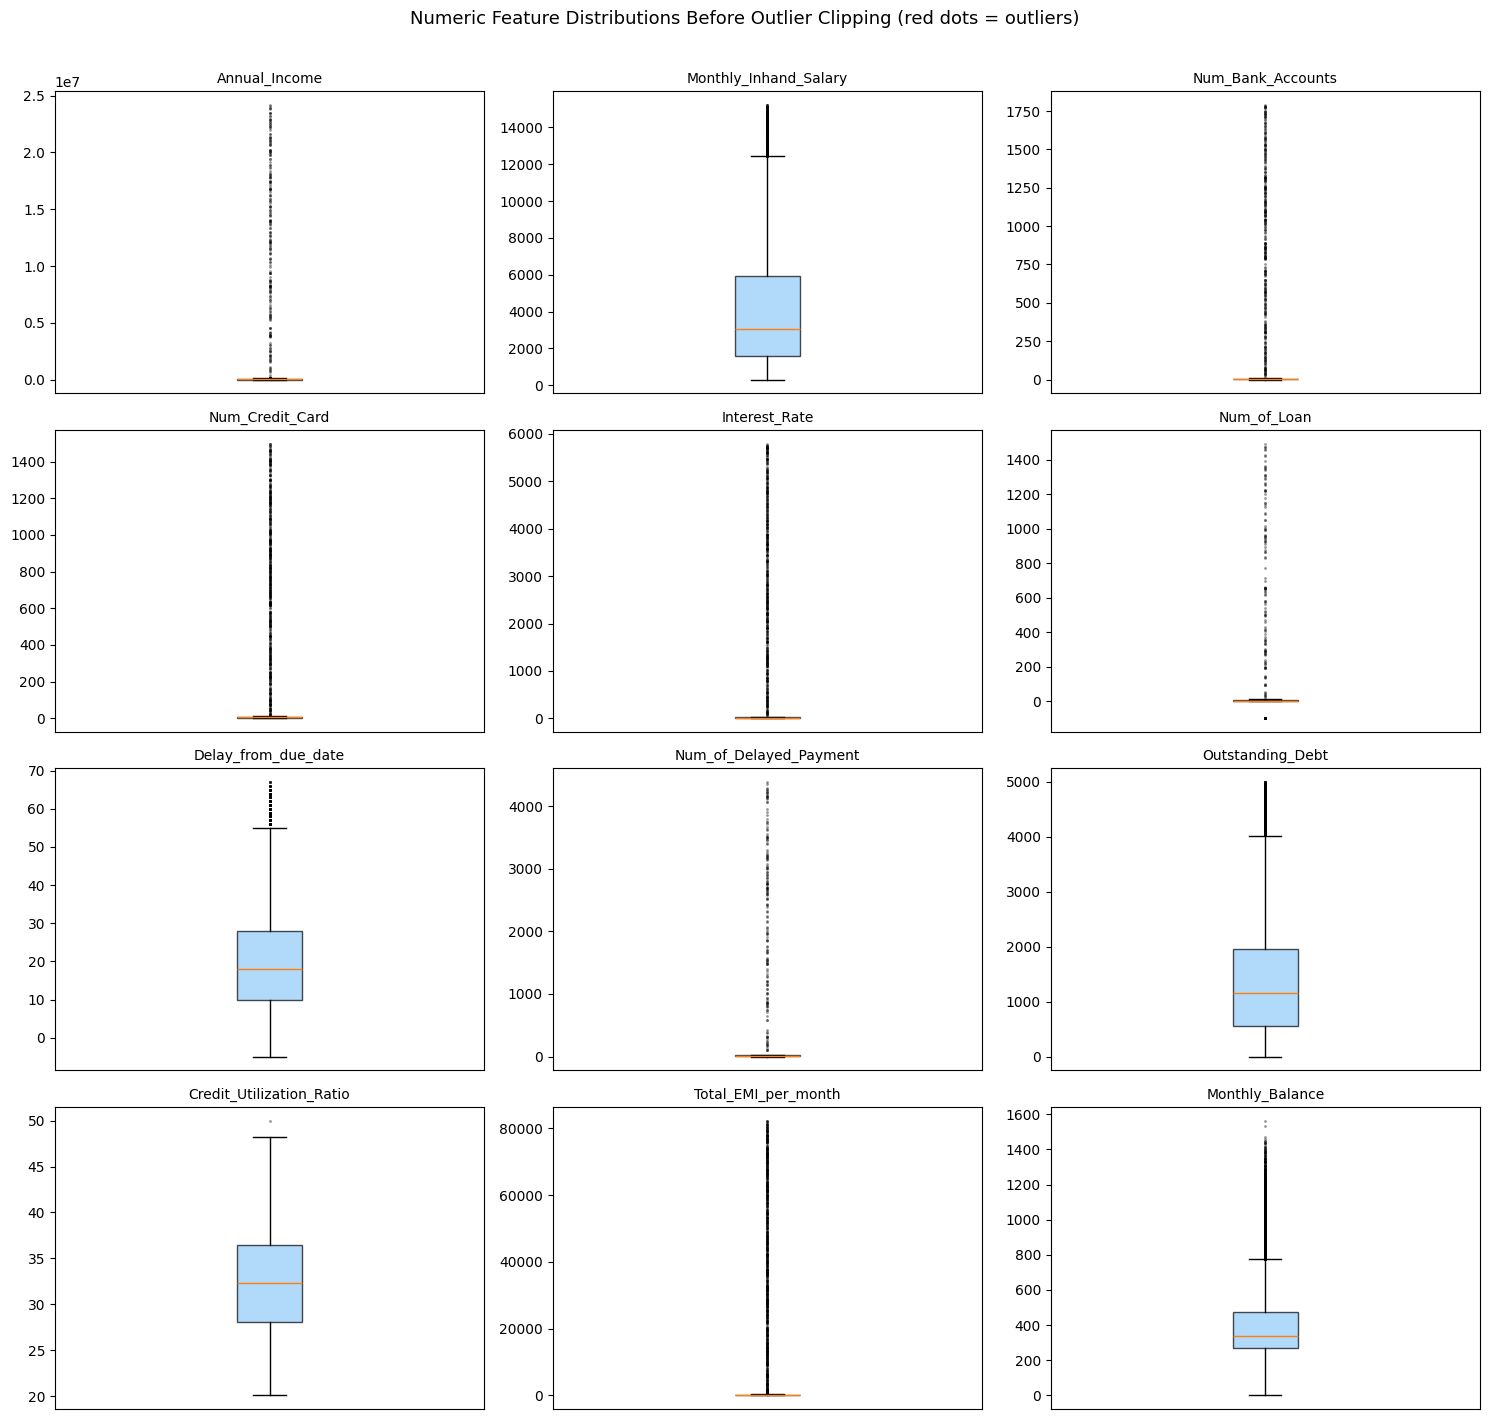

All numeric features are clipped at [p1, p99] during preprocessing to reduce outlier influence.


In [6]:
# Strip dirty suffixes for visualization (same helper used in boxplots below)
def _try_numeric(series):
    if series.dtype == object:
        return pd.to_numeric(series.astype(str).str.strip().str.rstrip("_"), errors="coerce")
    return series

numeric_cols_for_plot = [
    "Annual_Income", "Monthly_Inhand_Salary", "Num_Bank_Accounts",
    "Num_Credit_Card", "Interest_Rate", "Num_of_Loan",
    "Delay_from_due_date", "Num_of_Delayed_Payment", "Outstanding_Debt",
    "Credit_Utilization_Ratio", "Total_EMI_per_month", "Monthly_Balance"
]

plot_df = pd.DataFrame()
for col in numeric_cols_for_plot:
    plot_df[col] = _try_numeric(df[col])
plot_df["Credit_Score"] = df["Credit_Score"]

# Outlier count table: values beyond [p1, p99]
print("=== Outlier Count per Feature (beyond [1st, 99th] percentile) ===")
outlier_rows = []
for col in numeric_cols_for_plot:
    s = plot_df[col].dropna()
    p1, p99 = s.quantile(0.01), s.quantile(0.99)
    n_out = ((s < p1) | (s > p99)).sum()
    outlier_rows.append({
        "feature"       : col,
        "p1"            : round(p1, 2),
        "p99"           : round(p99, 2),
        "n_outliers"    : n_out,
        "pct_outliers"  : round(n_out / len(s) * 100, 2),
    })
outlier_df = pd.DataFrame(outlier_rows).sort_values("n_outliers", ascending=False)
display(outlier_df)

# Box plots with outliers visible (showfliers=True) to see extent before clipping
fig, axes = plt.subplots(4, 3, figsize=(15, 14))
for ax, col in zip(axes.flatten(), numeric_cols_for_plot):
    ax.boxplot(plot_df[col].dropna(), patch_artist=True,
               boxprops=dict(facecolor="#90CAF9", alpha=0.7),
               flierprops=dict(marker=".", markersize=2, color="#E53935", alpha=0.4))
    ax.set_title(col, fontsize=10)
    ax.set_xticks([])
plt.suptitle("Numeric Feature Distributions Before Outlier Clipping (red dots = outliers)",
             y=1.01, fontsize=13)
plt.tight_layout()
plt.show()

print("All numeric features are clipped at [p1, p99] during preprocessing to reduce outlier influence.")

### 3.4 Numeric Feature Distribution per Class

Box plots compare numeric feature distributions across Credit Score classes.
Features with a clear separation between classes are the strongest candidate predictors for the model.

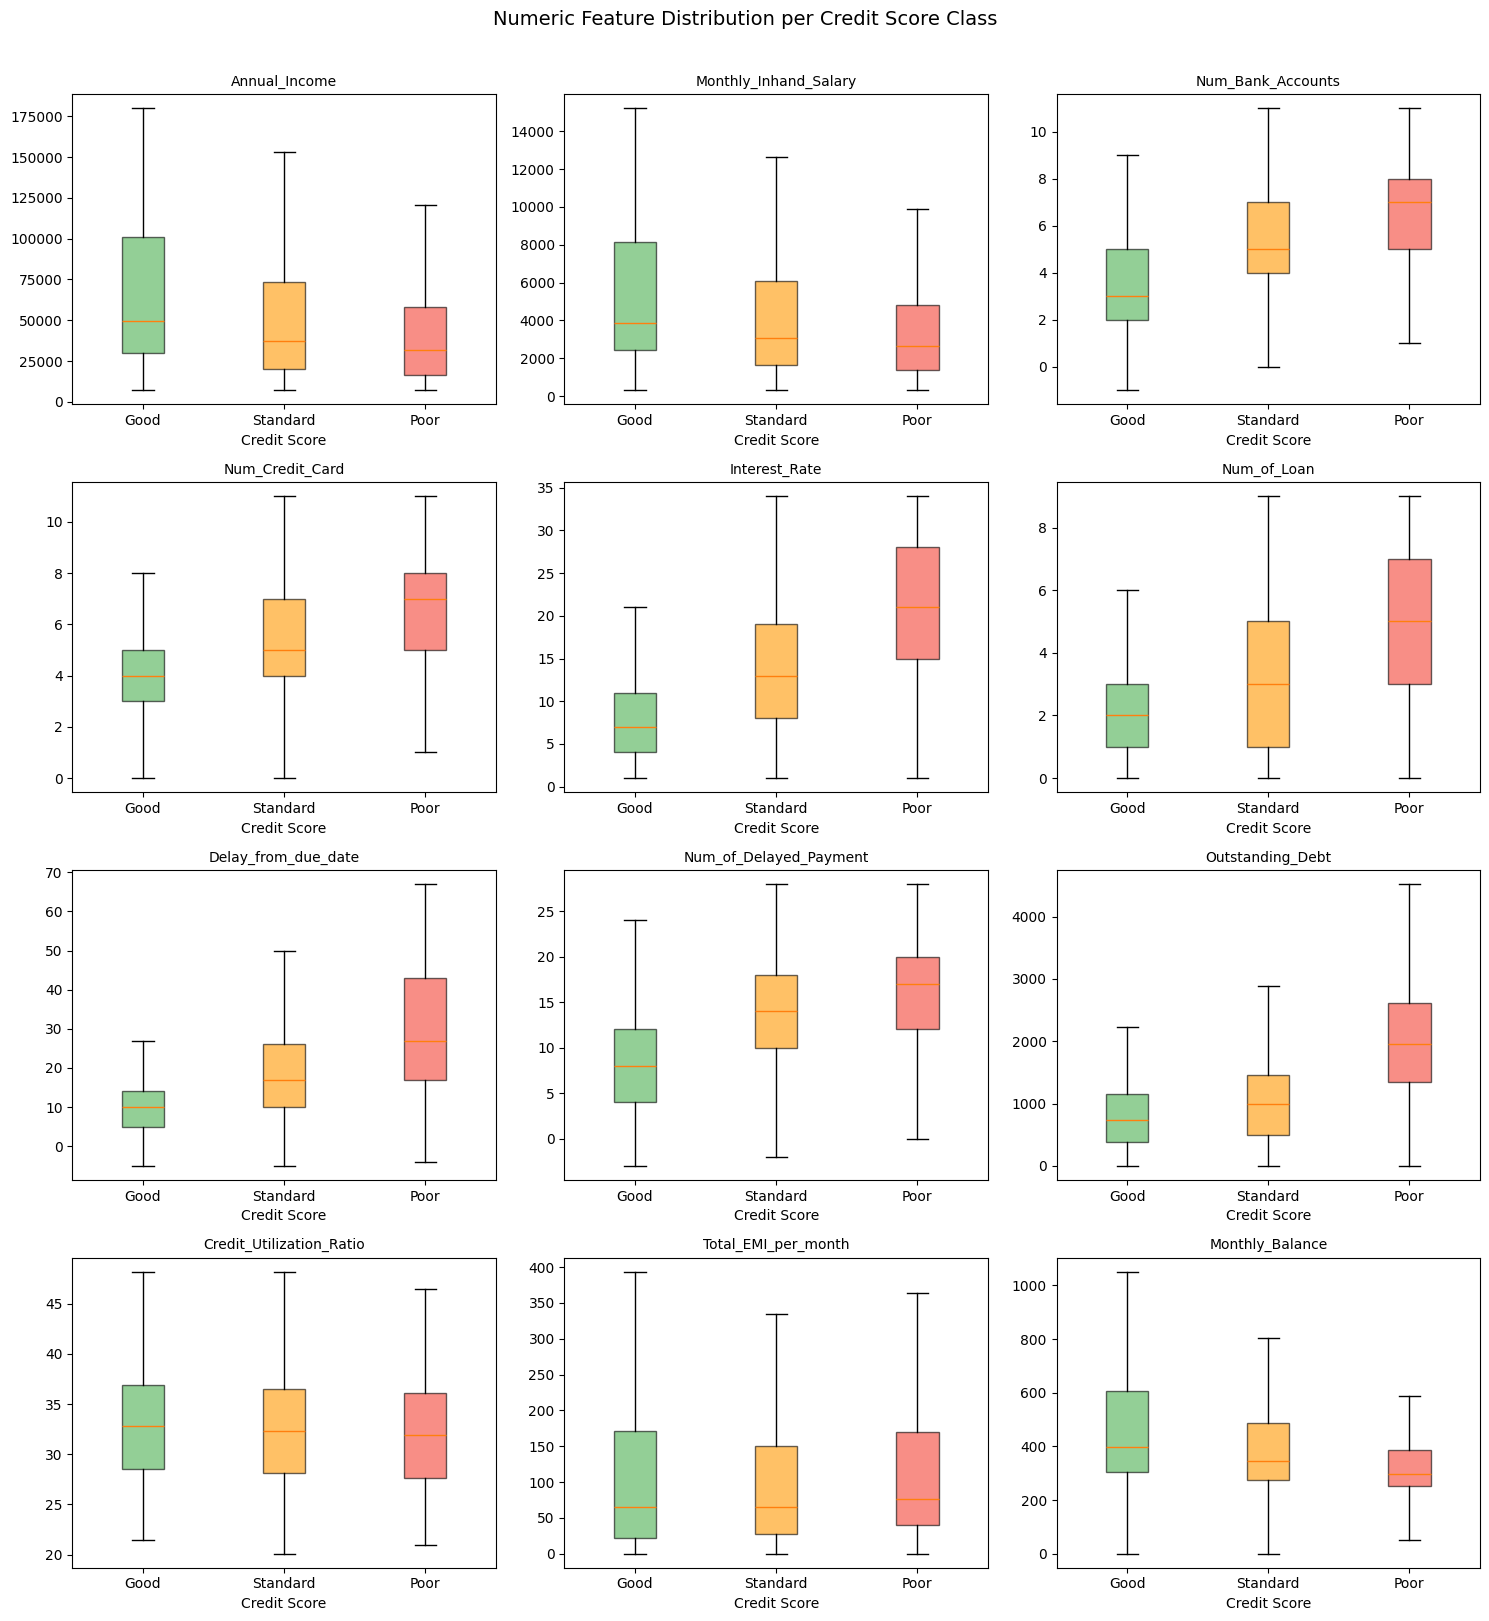

In [7]:
class_order = ["Good", "Standard", "Poor"]

fig, axes = plt.subplots(4, 3, figsize=(15, 16))
for ax, col in zip(axes.flatten(), numeric_cols_for_plot):
    data_per_class = [plot_df[plot_df["Credit_Score"]==c][col].dropna() for c in class_order]
    bp = ax.boxplot(data_per_class, labels=class_order, patch_artist=True, showfliers=False)
    colors = ["#4CAF50", "#FF9800", "#F44336"]
    for patch, color in zip(bp["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.6)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("Credit Score")
plt.suptitle("Numeric Feature Distribution per Credit Score Class", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

### 3.5 Categorical Feature Distribution per Class

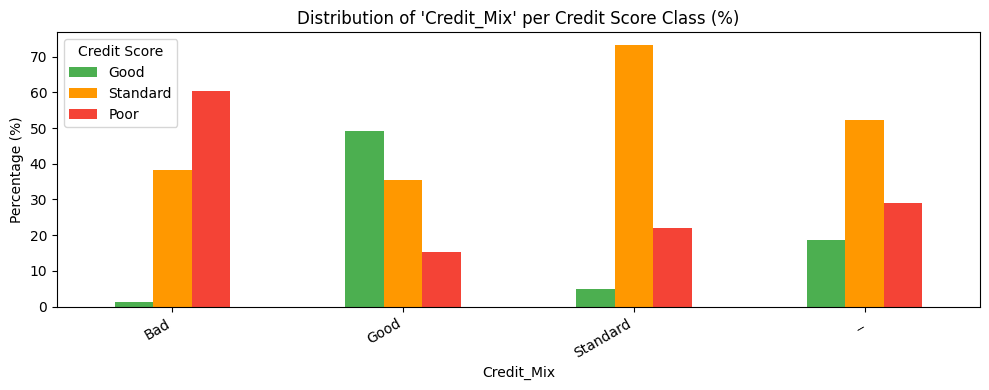

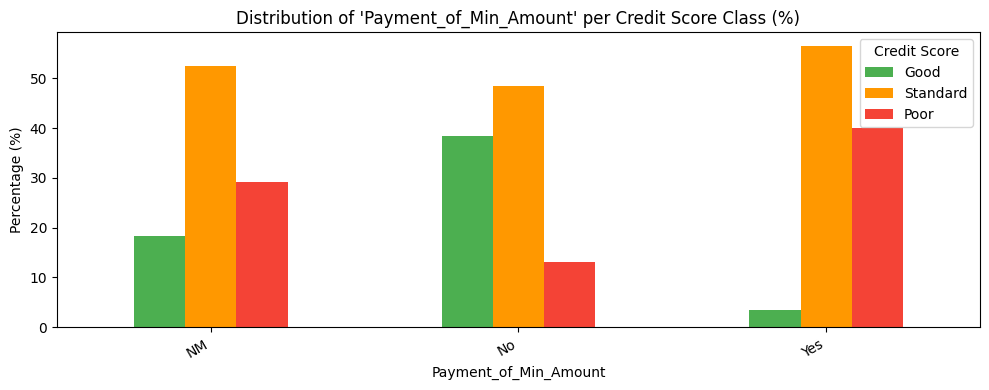

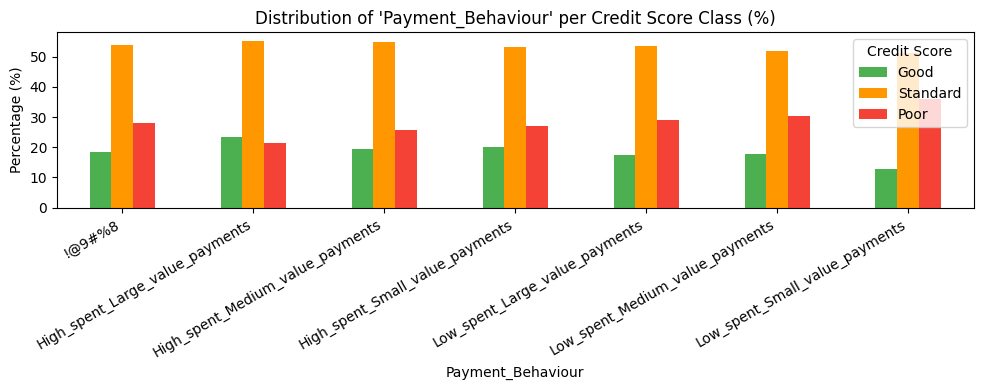

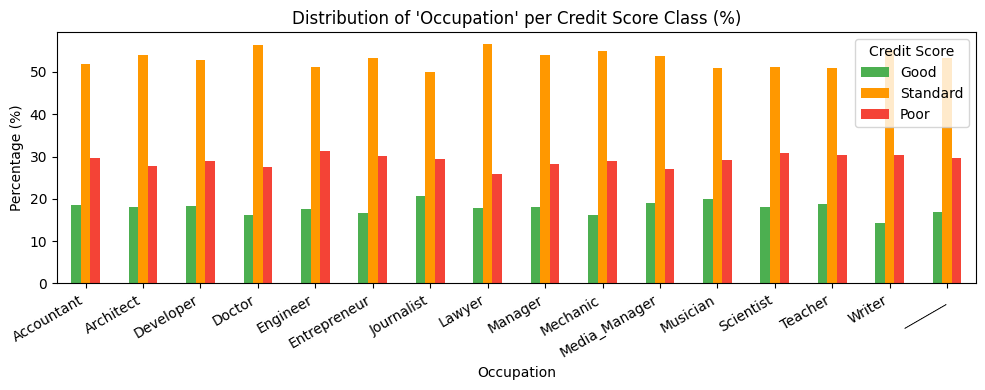

In [8]:
cat_cols_for_plot = ["Credit_Mix", "Payment_of_Min_Amount", "Payment_Behaviour", "Occupation"]

for col in cat_cols_for_plot:
    ct = pd.crosstab(df[col], df["Credit_Score"], normalize="index") * 100
    # Reorder columns to match class_order
    ct = ct[[c for c in class_order if c in ct.columns]]
    ct.plot(kind="bar", figsize=(10, 4), color=["#4CAF50", "#FF9800", "#F44336"])
    plt.title(f"Distribution of '{col}' per Credit Score Class (%)")
    plt.xlabel(col)
    plt.ylabel("Percentage (%)")
    plt.xticks(rotation=30, ha="right")
    plt.legend(title="Credit Score")
    plt.tight_layout()
    plt.show()

### 3.6 Correlation Heatmap (Numeric Features)

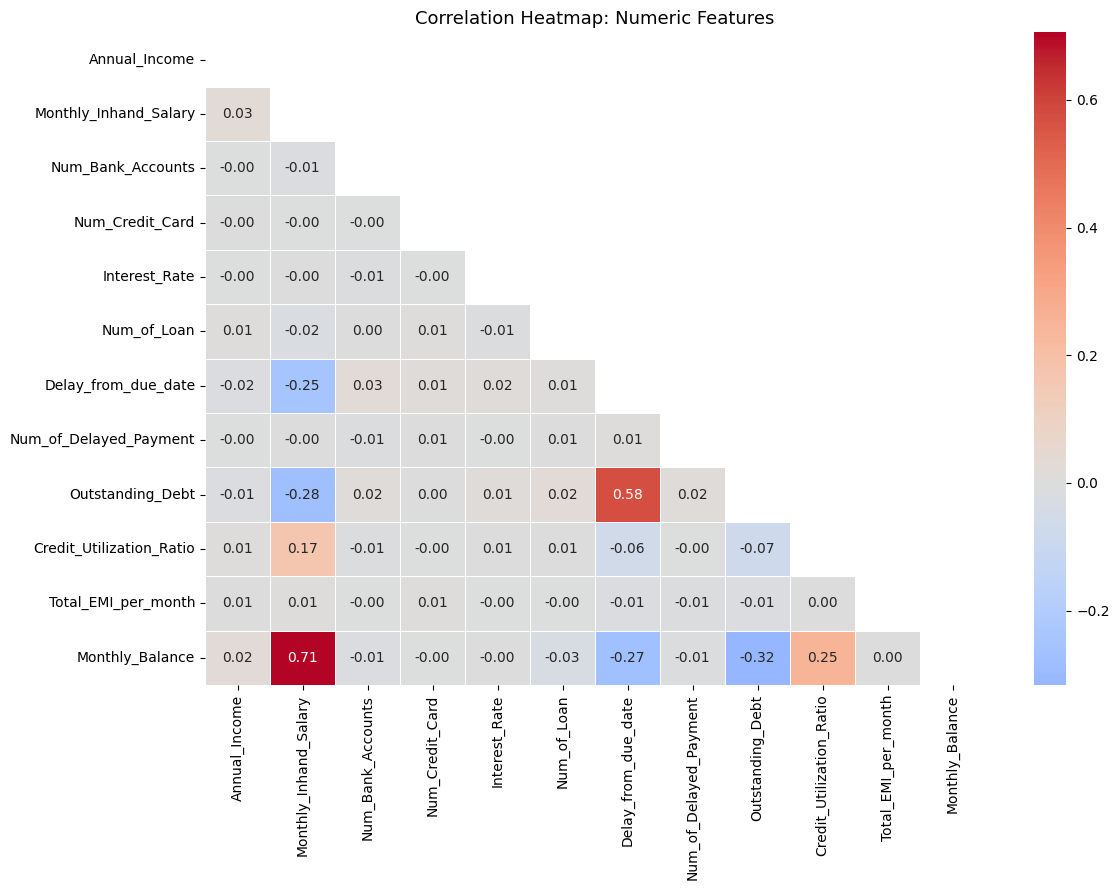

In [9]:
corr = plot_df[numeric_cols_for_plot].corr()
fig, ax = plt.subplots(figsize=(12, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, linewidths=0.5, ax=ax)
ax.set_title("Correlation Heatmap: Numeric Features", fontsize=13)
plt.tight_layout()
plt.show()

## 4. Preprocessing and Feature Engineering

Preprocessing is handled by the `CreditDataPreprocessor` class using the following steps in order:

| Step | Detail |
|---|---|
| Drop identifier columns | `Unnamed: 0`, `ID`, `Customer_ID`, `Name`, `SSN` |
| Strip underscore suffix | Columns: `Age`, `Num_of_Loan`, `Num_of_Delayed_Payment`, `Annual_Income`, `Outstanding_Debt`, `Amount_invested_monthly` |
| Replace dirty categories | `Credit_Mix='_'` to NaN; `Payment_Behaviour='!@9#%8'` to NaN; `Occupation='_______'` to NaN |
| Parse Credit_History_Age | `"X Years and Y Months"` converted to total months (integer) |
| Feature engineering | `Debt_to_Income = Outstanding_Debt / (Annual_Income + 1)` and `EMI_to_Salary = Total_EMI_per_month / (Monthly_Inhand_Salary + 1)` |
| Outlier clipping | Values clipped at the 1st and 99th percentile, including engineered features |
| Numeric imputation | Median imputation |
| Categorical imputation | Most-frequent imputation |
| Categorical encoding | Ordinal encoding for `Credit_Mix` and `Payment_of_Min_Amount`; one-hot encoding for `Occupation`, `Payment_Behaviour`, and `Month` |
| Scaling | StandardScaler applied to all numeric features |
| Feature selection | SelectPercentile (f_classif, top 85%) |

In [10]:
preprocessor = CreditDataPreprocessor()
X = preprocessor.clean(df)
y = df["Credit_Score"].astype(str)

print(f"Shape after preprocessing: {X.shape}")
print(f"\nNumeric features ({len(X.select_dtypes(include='number').columns)}):")
print(X.select_dtypes(include="number").columns.tolist())
print(f"\nCategorical features ({len(X.select_dtypes(exclude='number').columns)}):")
print(X.select_dtypes(exclude="number").columns.tolist())

print("\nSample rows after preprocessing:")
display(X.head())

# Verify no missing values remain after cleaning
remaining_na = X.isnull().sum().sum()
print(f"\nTotal missing values after cleaning: {remaining_na}")

Shape after preprocessing: (25000, 25)

Numeric features (20):
['Age', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Total_EMI_per_month', 'Amount_invested_monthly', 'Monthly_Balance', 'Credit_History_Age_Months', 'Loan_Type_Count', 'Debt_to_Income', 'EMI_to_Salary']

Categorical features (5):
['Month', 'Occupation', 'Credit_Mix', 'Payment_of_Min_Amount', 'Payment_Behaviour']

Sample rows after preprocessing:


,Month,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_History_Age_Months,Loan_Type_Count,Debt_to_Income,EMI_to_Salary
0,August,35.0,Journalist,20364.570,1626.047500,6.0,8,32.0,3.0,23,9.0,10.30,11.0,Standard,2500.04,27.576478,Yes,26.168109,92.518976,High_spent_Small_value_payments,303.917665,116.0,3,0.122758,0.016083
1,August,46.0,Teacher,9786.860,951.571667,9.0,10,1663.0,2.0,58,14.0,15.53,6.0,Standard,2149.90,23.451285,Yes,11.564437,54.461748,Low_spent_Medium_value_payments,309.130981,NaN,2,0.219650,0.012140
2,June,19.0,Unknown,146880.840,12372.070000,1.0,6,2.0,1.0,25,4.0,5.04,1.0,Good,387.53,31.100297,No,98.031931,478.357472,High_spent_Small_value_payments,920.817597,291.0,1,0.002638,0.007923
3,April,39.0,Developer,23200.820,NaN,3.0,7,5.0,0.0,30,15.0,24.73,6.0,Standard,987.07,26.786925,Yes,0.000000,65.849835,Low_spent_Large_value_payments,391.890332,211.0,0,0.042543,NaN
4,April,20.0,Architect,11336.835,992.736250,4.0,822,14.0,6.0,30,19.0,16.44,7.0,Standard,177.98,24.001752,Yes,35.562731,NaN,Low_spent_Small_value_payments,228.245999,175.0,6,0.015698,0.035787



Total missing values after cleaning: 15178


## 5. Training Pipeline

The `CreditScorePipeline` class manages the full training workflow:

- **Stratified** 80/20 train-test split to preserve class proportions across both sets
- Cross-validation experiments across four candidate models: Logistic Regression, Random Forest, Extra Trees, and Gradient Boosting
- Model selection is based on **weighted F1-score** because the dataset is imbalanced and accuracy would be misleading
- The best model is saved as a `.pkl` artifact along with its metadata and feature list
- Each run is logged to a local log file and optionally tracked in MLflow when it is installed

In [11]:
pipeline = CreditScorePipeline(
    log_path=str(ROOT / "logs" / "notebook_pipeline.log")
)
metadata = pipeline.run(
    data_path=str(DATA_PATH),
    model_out=str(MODEL_PATH),
    metrics_out=str(METRICS_PATH),
    tune=False,
)

print(f"Best model         : {metadata['best_model']}")
print(f"Test Accuracy      : {metadata['test_accuracy']:.4f}")
print(f"Test Weighted F1   : {metadata['test_f1_weighted']:.4f}")

2026-06-07 20:12:46,012 | INFO | Reading dataset from C:\Samuel\Kuliah\Semester 4\Model Deployment (MD)\dsnfonavhu oefraaw\credit_score_project\data\data_C.csv
2026-06-07 20:12:46,409 | INFO | Raw shape: (25000, 29)
2026-06-07 20:12:46,409 | INFO | Clean feature shape: (25000, 25)
2026-06-07 20:12:46,409 | INFO | Class distribution: {'Standard': 13282, 'Poor': 7268, 'Good': 4450}
2026/06/07 20:12:47 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following va

{
  "best_model": "random_forest",
  "test_accuracy": 0.7092,
  "test_f1_weighted": 0.7127
}
Best model         : random_forest
Test Accuracy      : 0.7092
Test Weighted F1   : 0.7127


### 5.1 Experiment Tracking with MLflow

Each pipeline run is automatically logged to MLflow when it is installed.
The cell below reads the tracked experiments directly from the local `mlruns/` folder
and displays them without requiring the MLflow UI to be running.

In [12]:
try:
    import mlflow

    client = mlflow.tracking.MlflowClient()

    # Find the credit_score_classification experiment
    exp = client.get_experiment_by_name("credit_score_classification")
    if exp is None:
        print("No MLflow experiment found. Run the pipeline first.")
    else:
        runs = client.search_runs(
            experiment_ids=[exp.experiment_id],
            order_by=["metrics.test_f1_weighted DESC"],
            max_results=10,
        )
        rows = []
        for r in runs:
            rows.append({
                "run_id"           : r.info.run_id[:8],
                "model"            : r.data.params.get("model", "-"),
                "test_accuracy"    : round(r.data.metrics.get("test_accuracy", 0), 4),
                "test_f1_weighted" : round(r.data.metrics.get("test_f1_weighted", 0), 4),
                "status"           : r.info.status,
            })
        if rows:
            mlflow_df = pd.DataFrame(rows)
            print(f"Experiment: {exp.name}")
            print(f"Total runs logged: {len(runs)}")
            print()
            display(mlflow_df)
        else:
            print("Experiment exists but has no runs yet.")

except ImportError:
    print("MLflow is not installed. Install it with: pip install mlflow")
    print("Pipeline still runs and saves model without MLflow.")

Experiment: credit_score_classification
Total runs logged: 10



,run_id,model,test_accuracy,test_f1_weighted,status
0,dcf7bfd0,random_forest,0.7092,0.7127,FINISHED
1,5e27613d,-,0.7092,0.7127,FINISHED
2,f87ce215,random_forest,0.7092,0.7127,FINISHED
3,b5f05d6f,-,0.7092,0.7127,FINISHED
4,125bead9,random_forest,0.7092,0.7127,FINISHED
5,b2c98082,-,0.7092,0.7127,FINISHED
6,58dba7ca,random_forest,0.7092,0.7127,FINISHED
7,1e542f01,-,0.7092,0.7127,FINISHED
8,260ea670,gradient_boosting,0.7000,0.6996,FINISHED
9,e0f69964,gradient_boosting,0.7000,0.6996,FINISHED


## 6. Model Comparison

All four candidate models are evaluated on the held-out test set using **weighted F1-score**.
This metric accounts for class imbalance by weighting each class proportionally to its support,
making it more appropriate than accuracy when class sizes differ significantly.

The table below shows cross-validation F1 (used for selection) alongside final test F1
to confirm the selected model generalises beyond the training data.

,model,cv_f1_weighted_mean,cv_f1_weighted_std,test_accuracy,test_precision_weighted,test_recall_weighted,test_f1_weighted
1,random_forest,0.6906,0.0100,0.7092,0.7400,0.7092,0.7127
3,gradient_boosting,0.6758,0.0061,0.7000,0.7014,0.7000,0.6996
2,extra_trees,0.6675,0.0023,0.6682,0.7236,0.6682,0.6718
0,logistic_regression,0.5881,0.0053,0.5974,0.6572,0.5974,0.5985


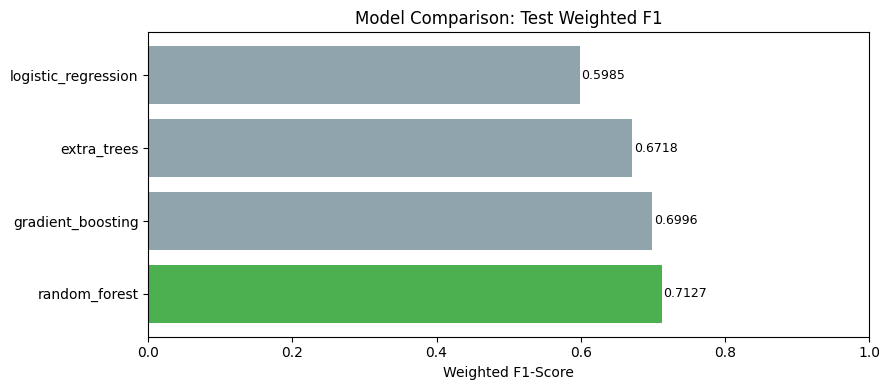

Selected model: random_forest
Test weighted F1: 0.7127

Selection rationale:
  Weighted F1 is used instead of accuracy because the dataset is imbalanced.
  The selected model produced the highest test weighted F1 across all candidates,
  meaning it performs best across all three classes when weighted by class size.


In [13]:
experiments = pd.DataFrame(metadata["experiments"]).sort_values("test_f1_weighted", ascending=False)
display(experiments)

# Visualise model comparison
fig, ax = plt.subplots(figsize=(9, 4))
colors = ["#4CAF50" if i == 0 else "#90A4AE" for i in range(len(experiments))]
bars = ax.barh(experiments["model"], experiments["test_f1_weighted"], color=colors)
for bar, val in zip(bars, experiments["test_f1_weighted"]):
    ax.text(val + 0.002, bar.get_y() + bar.get_height()/2,
            f"{val:.4f}", va="center", fontsize=9)
ax.set_xlabel("Weighted F1-Score")
ax.set_title("Model Comparison: Test Weighted F1")
ax.set_xlim(0, 1.0)
plt.tight_layout()
plt.show()

best = experiments.iloc[0]
print(f"Selected model: {best['model']}")
print(f"Test weighted F1: {best['test_f1_weighted']:.4f}")
print()
print("Selection rationale:")
print("  Weighted F1 is used instead of accuracy because the dataset is imbalanced.")
print("  The selected model produced the highest test weighted F1 across all candidates,")
print("  meaning it performs best across all three classes when weighted by class size.")

## 7. Final Evaluation on Held-Out Test Set

Comprehensive evaluation using three complementary views:

- **Confusion Matrix** to see per-class error patterns and understand which classes are being confused
- **Classification Report** showing precision, recall, and F1 for each class individually
- **Weighted F1** as the single primary metric, appropriate for imbalanced multi-class problems

Final deployed model : random_forest
Test Accuracy        : 0.7092
Test Weighted F1     : 0.7127


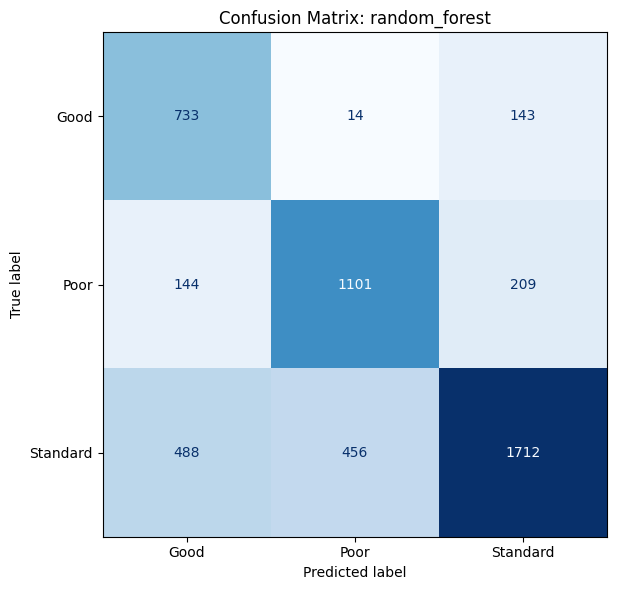


=== Classification Report ===


,precision,recall,f1-score,support
Good,0.536996,0.823596,0.650111,890.000000
Poor,0.700827,0.757221,0.727934,1454.000000
Standard,0.829457,0.644578,0.725424,2656.000000
accuracy,0.709200,0.709200,0.709200,0.709200
macro avg,0.689094,0.741798,0.701156,5000.000000
weighted avg,0.739994,0.709200,0.712748,5000.000000


In [14]:
artifact = joblib.load(MODEL_PATH)
model    = artifact["model"]
meta     = artifact["metadata"]
classes  = meta["classes"]

print(f"Final deployed model : {meta['best_model']}")
print(f"Test Accuracy        : {meta['test_accuracy']:.4f}")
print(f"Test Weighted F1     : {meta['test_f1_weighted']:.4f}")

# Confusion Matrix
cm_array = np.array(meta["confusion_matrix"])
fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_array, display_labels=classes)
disp.plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Confusion Matrix: {meta['best_model']}", fontsize=12)
plt.tight_layout()
plt.show()

# Classification Report
print("\n=== Classification Report ===")
report_df = pd.DataFrame(meta["classification_report"]).T
display(report_df.style.background_gradient(subset=["f1-score"], cmap="RdYlGn"))

## 8. Learning Curve

The learning curve shows how model performance changes as more training data is used.
A large gap between the training and validation curves indicates overfitting.
When both curves converge at a low score, the model is underfitting.
If the validation curve is still rising at full data size, collecting more data would likely help.

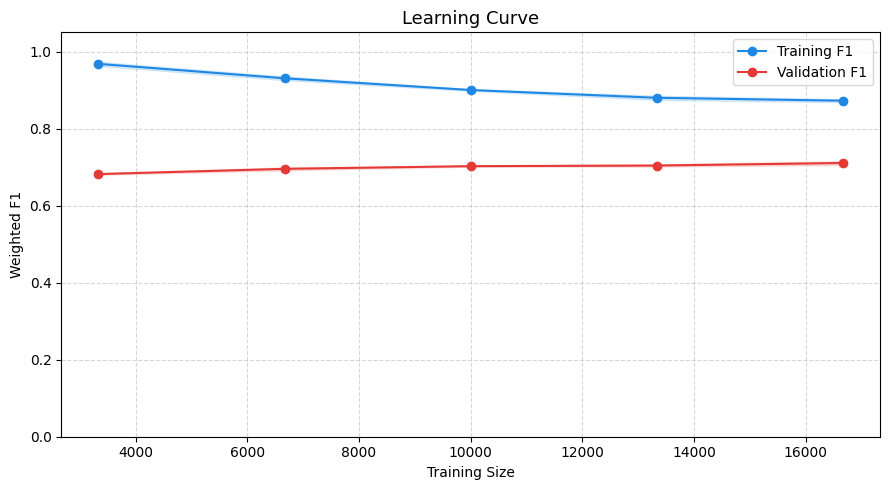

Train F1 at full data  : 0.8725
Valid F1 at full data  : 0.7107
Gap (train minus valid): 0.1618
Gap is relatively large. The model may be overfitting; consider stronger regularisation.


In [15]:
X_clean = preprocessor.clean(df)
y_clean = df["Credit_Score"].astype(str)

train_sizes, train_scores, valid_scores = learning_curve(
    model,
    X_clean,
    y_clean,
    cv=3,
    scoring="f1_weighted",
    train_sizes=np.linspace(0.2, 1.0, 5),
    n_jobs=1,
)

train_mean = train_scores.mean(axis=1)
train_std  = train_scores.std(axis=1)
valid_mean = valid_scores.mean(axis=1)
valid_std  = valid_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(train_sizes, train_mean, "o-", color="#1E88E5", label="Training F1")
ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std,
                alpha=0.15, color="#1E88E5")
ax.plot(train_sizes, valid_mean, "o-", color="#E53935", label="Validation F1")
ax.fill_between(train_sizes, valid_mean - valid_std, valid_mean + valid_std,
                alpha=0.15, color="#E53935")
ax.set_title("Learning Curve", fontsize=13)
ax.set_xlabel("Training Size")
ax.set_ylabel("Weighted F1")
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

gap = train_mean[-1] - valid_mean[-1]
print(f"Train F1 at full data  : {train_mean[-1]:.4f}")
print(f"Valid F1 at full data  : {valid_mean[-1]:.4f}")
print(f"Gap (train minus valid): {gap:.4f}")
if gap > 0.1:
    print("Gap is relatively large. The model may be overfitting; consider stronger regularisation.")
else:
    print("Gap is small. The model generalises well to unseen data.")

## 9. Permutation Importance (Model Interpretation)

Permutation importance measures how much the model's weighted F1 drops when a single feature's values are randomly shuffled.
A large drop means the model relied heavily on that feature; a near-zero drop means the feature contributed little.

This method is model-agnostic and more reliable than built-in tree-based feature importances,
which tend to overestimate features with many unique values or categories.

=== Top 15 Most Important Features ===


,feature,importance_mean,importance_std
7,Interest_Rate,0.099381,0.007098
14,Outstanding_Debt,0.098226,0.003431
13,Credit_Mix,0.088874,0.008392
11,Changed_Credit_Limit,0.060415,0.003160
9,Delay_from_due_date,0.060325,0.003725
16,Payment_of_Min_Amount,0.050110,0.005009
21,Credit_History_Age_Months,0.030685,0.004406
10,Num_of_Delayed_Payment,0.029009,0.001135
23,Debt_to_Income,0.028563,0.003080
12,Num_Credit_Inquiries,0.025441,0.001209


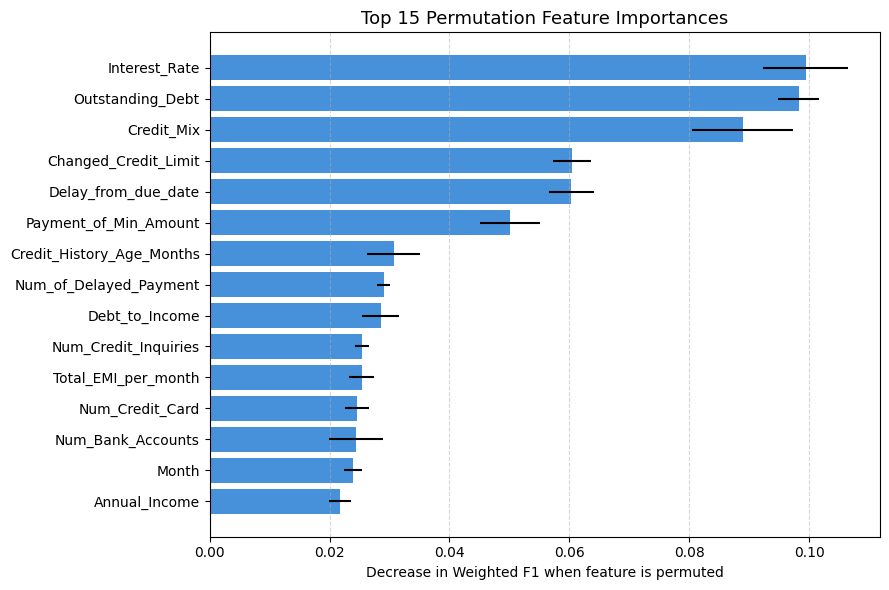

In [16]:
sample_df = df.sample(n=min(2000, len(df)), random_state=42)
X_sample  = preprocessor.clean(sample_df)
y_sample  = sample_df["Credit_Score"].astype(str)

perm_result = permutation_importance(
    model,
    X_sample,
    y_sample,
    n_repeats=5,
    random_state=42,
    scoring="f1_weighted",
    n_jobs=1,
)

perm_df = pd.DataFrame({
    "feature"        : artifact["feature_columns"],
    "importance_mean": perm_result.importances_mean,
    "importance_std" : perm_result.importances_std,
}).sort_values("importance_mean", ascending=False)

print("=== Top 15 Most Important Features ===")
display(perm_df.head(15))

top15 = perm_df.head(15).sort_values("importance_mean")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top15["feature"], top15["importance_mean"],
        xerr=top15["importance_std"], color="#1976D2", alpha=0.8)
ax.set_xlabel("Decrease in Weighted F1 when feature is permuted")
ax.set_title("Top 15 Permutation Feature Importances", fontsize=13)
ax.grid(True, axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## 10. Local vs Cloud Deployment: Comparison

This section addresses the advantages and disadvantages between running the pipeline and deployment locally
versus on a cloud platform such as AWS EC2.

| Dimension | Local | Cloud (AWS EC2) |
|---|---|---|
| **Setup time** | Minutes (pip install) | 15 to 30 minutes (provision instance, configure security groups, upload files) |
| **Cost** | Free | Ongoing instance cost (t2.micro ~$0.012/hour on AWS) |
| **Scalability** | Limited to local machine resources | Scale up instance type on demand |
| **Accessibility** | localhost only | Public IP, accessible from any device |
| **Availability** | Stops when machine sleeps or is shut down | Can run continuously with nohup or a process manager |
| **Data transfer** | No upload needed | Files must be uploaded via SCP or git |
| **Monitoring** | MLflow UI at localhost:5000 | Same MLflow UI, accessible at public IP:5000 |
| **Debugging** | Direct file access, fast iteration | Requires SSH to inspect logs |
| **Reproducibility** | Tied to local environment | Isolated VM, same environment every time |
| **Suitable for** | Development, experimentation, demos | Production serving, team collaboration |

**When to choose local:**
Running locally is best during active development and experimentation where fast iteration matters more than
availability. It is also sufficient for coursework demonstrations where the model only needs to run
on one machine.

**When to choose cloud:**
Cloud deployment is appropriate when the model needs to be accessible to multiple users,
when uptime requirements exist, or when the dataset or model is too large for a local machine.
For this project, deploying on AWS EC2 demonstrates that the same codebase runs identically
in a production-like environment without code changes.

## 11. Conclusion

| Aspect | Detail |
|---|---|
| **Dataset** | 25,000 records, 3 classes (Good, Standard, Poor), imbalanced |
| **Features used** | All financial features after dropping identifier columns (ID, Name, SSN, Customer_ID) |
| **Key preprocessing** | Strip dirty suffixes, parse Credit_History_Age to months, engineer Debt_to_Income and EMI_to_Salary, clip outliers at [p1, p99], median/mode imputation, encoding, scaling |
| **Evaluation metric** | Weighted F1-score (chosen because the dataset is imbalanced) |
| **Best model** | See Section 6 output, selected by highest test weighted F1 across 4 candidates |
| **Experiment tracking** | MLflow logs all runs to mlruns/ with parameters, metrics, and artifact paths |
| **Saved artifact** | `models/model_best.pkl` contains the model, metadata, and feature column list |

The saved model artifact is used directly by the Streamlit application for real-time single-customer
and batch inferencing. It can be retrained at any time by re-running the local pipeline with updated data.